# Five Agent Types, One Procurement Problem




| # | Agent type | What it adds | The question it can now answer |
|---|---|---|---|
| 1 | **Simple reflex** | condition → action rules | *"What do I do when I see this?"* |
| 2 | **Model-based reflex** | internal **state** + a model of how its actions change the world | *"What is the world like now, including the parts I can't see?"* |
| 3 | **Goal-based** | an explicit **goal** + look-ahead over plans | *"Will this plan get me to the goal?"* |
| 4 | **Utility-based** | a **utility** score over outcomes | *"Of all the plans that work, which is best?"* |
| 5 | **Learning** | a **critic**, a **learning element** and a **problem generator** | *"How do I do better next time?"* |

Each class **inherits from the one before** and adds exactly one idea, marked in the code with `# >>> BECOMES ...`.

**Runs anywhere:** plain Python, no GPU, no model download, no API key. In Colab: *Runtime → Run all* (about 5 seconds).

## 1 · The world

The world is the same for every agent:

- **Eight catalog items** (the lab's prices).
- **Two suppliers** with a trade-off:
  - **CampusMart** is cheaper but slower: 5 days, advertises 95% on time.
  - **QuickKart** costs 10% more but is faster: 2 days, advertises 90% on time.


In [ ]:
import itertools, random
from copy import deepcopy

GST = 0.18
LATE_PENALTY = 800      # ₹ cost of one order line arriving late (a lab session rescheduled)

ITEMS = {               # sku: (name, price before GST at the base rate)
    "NB-A5":   ("Notebook A5, 200 pages",     85),
    "PEN-BL":  ("Ball pen, blue",             12),
    "PEN-GEL": ("Gel pen, black",             25),
    "WB-MRK":  ("Whiteboard marker",          55),
    "STK-PAD": ("Sticky notes pad",           40),
    "USB-32":  ("USB drive 32 GB",           449),
    "HDMI-2M": ("HDMI cable 2 m",            299),
    "EXT-4":   ("Extension board, 4 sockets", 649),
}

# Listed in the order a plan search tries them. Nothing in this order says which one is better.
SUPPLIERS = {
    "QuickKart":  {"markup": 1.10, "days": 2, "advertised_on_time": 0.90},
    "CampusMart": {"markup": 1.00, "days": 5, "advertised_on_time": 0.95},
}
TRUE_ON_TIME = {"QuickKart": 0.92, "CampusMart": 0.55}     # hidden from every agent

START_STOCK = {
    "CampusMart": {"NB-A5": 40, "PEN-BL": 200, "PEN-GEL": 100, "WB-MRK": 30, "STK-PAD": 60,
                   "USB-32": 8, "HDMI-2M": 5, "EXT-4": 6},
    "QuickKart":  {"NB-A5": 100, "PEN-BL": 50, "WB-MRK": 20, "STK-PAD": 20,
                   "USB-32": 20, "HDMI-2M": 10, "EXT-4": 10},
}

# What a word in the request means (shared by all agents, so we compare decision-making, not parsing)
SKU_FOR = {"notebook": "NB-A5", "ball pen": "PEN-BL", "gel pen": "PEN-GEL", "marker": "WB-MRK",
           "sticky": "STK-PAD", "usb": "USB-32", "hdmi": "HDMI-2M", "extension": "EXT-4"}

def unit_price(supplier, sku):
    return ITEMS[sku][1] * SUPPLIERS[supplier]["markup"]

def total_with_gst(lines):
    """lines = [(supplier, sku, qty), ...]"""
    return round(sum(q * unit_price(s, k) for s, k, q in lines) * (1 + GST), 2)

print("CampusMart-only cost of the lecture order T1:",
      total_with_gst([("CampusMart", "NB-A5", 30), ("CampusMart", "PEN-BL", 60), ("CampusMart", "USB-32", 4)]))

CampusMart-only cost of the lecture order T1: 5977.88


In [ ]:
class ProcurementWorld:
    """The environment. Agents perceive it through read_catalog() and act on it through place()."""

    def __init__(self, seed=0):
        self.seed, self.week = seed, 1
        self.stock = deepcopy(START_STOCK)       # the TRUE, live stock
        self.snapshot = deepcopy(START_STOCK)    # what the catalog page shows

    def read_catalog(self):
        """PERCEPT. Stock figures are from the weekly refresh, not live."""
        return {"week": self.week,
                "offers": [{"supplier": s, "sku": k, "stock": q,
                            "unit_price": unit_price(s, k), "days": SUPPLIERS[s]["days"],
                            "advertised_on_time": SUPPLIERS[s]["advertised_on_time"]}
                           for s in SUPPLIERS for k, q in self.snapshot[s].items()]}

    def place(self, supplier, sku, qty):
        """ACTION. Ships what is really in stock; the rest is short."""
        shipped = min(qty, self.stock[supplier].get(sku, 0))
        self.stock[supplier][sku] = self.stock[supplier].get(sku, 0) - shipped
        return {"supplier": supplier, "sku": sku, "asked": qty, "shipped": shipped,
                "cost": total_with_gst([(supplier, sku, shipped)])}

    def on_time(self, order_id, supplier, sku, deadline_days):
        """Hidden outcome, revealed only after ordering. Same draw for every agent (fair comparison)."""
        if SUPPLIERS[supplier]["days"] > deadline_days:
            return False
        r = random.Random(f"{self.seed}-{self.week}-{order_id}-{supplier}-{sku}").random()
        return r < TRUE_ON_TIME[supplier]

    def new_week(self):
        """Restock, and refresh the catalog page."""
        self.week += 1
        self.stock = deepcopy(START_STOCK)
        self.snapshot = deepcopy(START_STOCK)

### The orders

T1 to T4 are the lab's orders. **T5** is new: two items, a comfortable budget and **more than one plan that works**, which is the situation where goal-based and utility-based agents start to differ.

| Order | Items | Budget (incl. GST) | Needed in | The trap |
|---|---|---|---|---|
| T1 | 30 notebooks, 60 ball pens, 4 USB drives | ₹6,000 | 7 days | none: ₹5,977.88 just fits |
| T2 | 10 markers, 5 sticky pads | ₹800 | 7 days | costs ₹885: impossible |
| T3 | 2 HDMI cables, 3 extension boards | ₹3,000 | 5 days | ₹3,003.10: over by ₹3.10 |
| T4 | 10 USB drives | ₹10,000 | **3 days** | CampusMart is too slow, and has only 4 left after T1 |
| T5 | 20 notebooks, 2 HDMI cables | ₹4,000 | 7 days | only 10 notebooks left at CampusMart after T1 |

The orders arrive **one after another in the same week**, so earlier orders use up stock that the catalog page still shows.

In [ ]:
ORDERS = {
    "T1": {"lines": {"notebook": 30, "ball pen": 60, "usb": 4}, "budget": 6000,  "deadline_days": 7},
    "T2": {"lines": {"marker": 10, "sticky": 5},                "budget": 800,   "deadline_days": 7},
    "T3": {"lines": {"hdmi": 2, "extension": 3},                "budget": 3000,  "deadline_days": 5},
    "T4": {"lines": {"usb": 10},                                "budget": 10000, "deadline_days": 3},
    "T5": {"lines": {"notebook": 20, "hdmi": 2},                "budget": 4000,  "deadline_days": 7},
}

### The harness

One function runs any agent on one order. The agent never touches the world directly. It sees a percept, returns a decision, and is told what happened.

1. **Perceive:** `catalog = world.read_catalog()`.
2. **Decide:** `agent.decide(order, catalog)` returns the lines to place, or none (escalate to a human).
3. **Act:** each line is placed and the world returns confirmations.
4. **Observe:** `agent.observe(confirmations)`. An agent may use or ignore this.
5. **Deliveries arrive:** `agent.learn(deliveries)` is called if the agent has it. Only the learning agent does.

In [ ]:
def run_order(agent, world, order_id, verbose=True):
    order = ORDERS[order_id] if isinstance(order_id, str) else order_id[1]
    oid = order_id if isinstance(order_id, str) else order_id[0]
    catalog = world.read_catalog()                       # 1 perceive
    decision = agent.decide(order, catalog)              # 2 decide
    confs = [world.place(*line) for line in decision["lines"]]   # 3 act
    agent.observe(confs)                                 # 4 observe
    deliveries = [(c["supplier"], world.on_time(oid, c["supplier"], c["sku"], order["deadline_days"]))
                  for c in confs if c["shipped"] > 0]
    if hasattr(agent, "learn"):                          # 5 learn (only learning agents)
        agent.learn(deliveries)

    spent = round(sum(c["cost"] for c in confs), 2)
    short = [f'{c["sku"]} {c["shipped"]}/{c["asked"]}' for c in confs if c["shipped"] < c["asked"]]
    slow  = [c["supplier"] for c in confs if SUPPLIERS[c["supplier"]]["days"] > order["deadline_days"]]
    late  = sum(1 for _, ok in deliveries if not ok)
    if not confs:                    verdict = "escalated"
    elif spent > order["budget"]:    verdict = "BROKE BUDGET"
    elif short:                      verdict = "SHORT"
    elif slow:                       verdict = "TOO SLOW"
    else:                            verdict = "goal met"
    if verbose:
        print(f"[{oid}] {decision['note']}")
        for c in confs:
            print(f"      {c['supplier']:<10} {c['sku']:<8} asked {c['asked']:>3}  shipped {c['shipped']:>3}  ₹{c['cost']:>9,.2f}")
        print(f"      spent ₹{spent:,.2f} of ₹{order['budget']:,}  ->  {verdict}"
              + (f"  (short: {', '.join(short)})" if short else "")
              + (f"  ({len(slow)} line(s) slower than {order['deadline_days']} days)" if slow else ""))
    return {"order": oid, "verdict": verdict, "spent": spent, "late_lines": late,
            "realised_cost": spent + LATE_PENALTY * late}

def run_week(agent, order_ids=("T1", "T2", "T3", "T4", "T5"), seed=0, verbose=True):
    world = ProcurementWorld(seed)
    return [run_order(agent, world, oid, verbose) for oid in order_ids]

---
## Agent 1 · Simple reflex

> **It is a simple reflex agent because** it maps the **current percept** straight to an action through fixed **condition → action rules**. It has no memory of earlier orders, no goal and no look-ahead.
>
> `IF the request says "usb" THEN order USB-32 from CampusMart, in the quantity asked.`

It never reads the stock, the budget or the deadline. It doesn't even need the catalog.

In [ ]:
class SimpleReflexAgent:
    # Condition -> action rules, written by the designer. Default supplier: the cheapest one.
    RULES = {item: ("CampusMart", sku) for item, sku in SKU_FOR.items()}

    def decide(self, order, catalog):
        lines = []
        for item, qty in order["lines"].items():
            supplier, sku = self.RULES[item]          # >>> SIMPLE REFLEX: percept -> rule -> action
            lines.append((supplier, sku, qty))
        return {"lines": lines, "note": "Reflex: one rule fired per item, nothing checked"}

    def observe(self, confirmations):
        pass                                          # no state, so feedback is thrown away

reflex_results = run_week(SimpleReflexAgent())

[T1] Reflex: one rule fired per item, nothing checked
      CampusMart NB-A5    asked  30  shipped  30  ₹ 3,009.00
      CampusMart PEN-BL   asked  60  shipped  60  ₹   849.60
      CampusMart USB-32   asked   4  shipped   4  ₹ 2,119.28
      spent ₹5,977.88 of ₹6,000  ->  goal met
[T2] Reflex: one rule fired per item, nothing checked
      CampusMart WB-MRK   asked  10  shipped  10  ₹   649.00
      CampusMart STK-PAD  asked   5  shipped   5  ₹   236.00
      spent ₹885.00 of ₹800  ->  BROKE BUDGET
[T3] Reflex: one rule fired per item, nothing checked
      CampusMart HDMI-2M  asked   2  shipped   2  ₹   705.64
      CampusMart EXT-4    asked   3  shipped   3  ₹ 2,297.46
      spent ₹3,003.10 of ₹3,000  ->  BROKE BUDGET
[T4] Reflex: one rule fired per item, nothing checked
      CampusMart USB-32   asked  10  shipped   4  ₹ 2,119.28
      spent ₹2,119.28 of ₹10,000  ->  SHORT  (short: USB-32 4/10)  (1 line(s) slower than 3 days)
[T5] Reflex: one rule fired per item, nothing checked
  

**Read the output:**
- **T1** passes, but only by luck: the rules happen to fit the order.
- **T2 and T3** break the budget, because the agent never added anything up.
- **T4 and T5** come back **short**. The agent doesn't know its own earlier orders emptied the shelf.
- **T4** is also **too slow**: CampusMart takes 5 days and the deadline was 3.

Each rule is reasonable on its own. What's missing is everything outside the current percept.

---
## Agent 2 · Model-based reflex

> **It becomes model-based when** it keeps an **internal state** about the parts of the world it cannot currently see, and updates that state with a **model of how its own actions change the world**.

Here the state is `believed_stock`:

```
believed stock  =  stock on the catalog page  −  what I have ordered since the page was refreshed
```

It is still a reflex agent. It still fires a rule per item, but now the rule's condition reads the state: *"IF the default supplier has enough (as I believe), use it; ELSE use another supplier that has enough."*

In [ ]:
class ModelBasedReflexAgent(SimpleReflexAgent):
    def __init__(self):
        self.believed_stock, self.week_seen = {}, None     # >>> BECOMES MODEL-BASED: internal state

    def update_state(self, catalog):
        if catalog["week"] != self.week_seen:              # a fresh catalog page: reset the belief
            self.believed_stock = {(o["supplier"], o["sku"]): o["stock"] for o in catalog["offers"]}
            self.week_seen = catalog["week"]

    def decide(self, order, catalog):
        self.update_state(catalog)
        lines, notes = [], []
        for item, qty in order["lines"].items():
            default, sku = self.RULES[item]
            supplier = default
            if self.believed_stock.get((default, sku), 0) < qty:       # condition reads the STATE
                others = [s for s in SUPPLIERS if self.believed_stock.get((s, sku), 0) >= qty]
                if others:
                    supplier = others[0]
                    notes.append(f"{sku}: {default} has only {self.believed_stock.get((default, sku), 0)}, using {supplier}")
            lines.append((supplier, sku, qty))
        return {"lines": lines, "note": "Model-based: " + ("; ".join(notes) or "rules fired, stock checked against my state")}

    def observe(self, confirmations):
        for c in confirmations:                            # >>> model of how MY actions change the world
            self.believed_stock[(c["supplier"], c["sku"])] -= c["shipped"]

model_results = run_week(ModelBasedReflexAgent())

[T1] Model-based: rules fired, stock checked against my state
      CampusMart NB-A5    asked  30  shipped  30  ₹ 3,009.00
      CampusMart PEN-BL   asked  60  shipped  60  ₹   849.60
      CampusMart USB-32   asked   4  shipped   4  ₹ 2,119.28
      spent ₹5,977.88 of ₹6,000  ->  goal met
[T2] Model-based: rules fired, stock checked against my state
      CampusMart WB-MRK   asked  10  shipped  10  ₹   649.00
      CampusMart STK-PAD  asked   5  shipped   5  ₹   236.00
      spent ₹885.00 of ₹800  ->  BROKE BUDGET
[T3] Model-based: rules fired, stock checked against my state
      CampusMart HDMI-2M  asked   2  shipped   2  ₹   705.64
      CampusMart EXT-4    asked   3  shipped   3  ₹ 2,297.46
      spent ₹3,003.10 of ₹3,000  ->  BROKE BUDGET
[T4] Model-based: USB-32: CampusMart has only 4, using QuickKart
      QuickKart  USB-32   asked  10  shipped  10  ₹ 5,828.02
      spent ₹5,828.02 of ₹10,000  ->  goal met
[T5] Model-based: NB-A5: CampusMart has only 10, using QuickKart
      Q

**What changed:**
- **T4 and T5** now ship in full. The agent *remembered* that T1 took 4 USB drives and 30 notebooks, even though the catalog page still shows the old figures.
- **T4** now meets the deadline, but only by accident: it switched to QuickKart for stock reasons, not because it knew about the deadline.
- **T2 and T3** still break the budget. The agent knows more about the world, but it still doesn't know what it is trying to achieve.

---
## Agent 3 · Goal-based

> **It becomes goal-based when** it has an **explicit description of the goal** and **looks ahead**. It uses its model to predict *"what happens if I do this?"* for whole plans, and acts only on a plan whose predicted outcome passes the goal test.

**Goal test:** every line fully in stock **and** total with GST ≤ budget **and** every supplier fast enough for the deadline.

- If no plan passes, the agent **places nothing and escalates** with the reason.
- The goal is **yes/no**. To this agent, every plan that passes is equally good, so it takes the **first** one its search finds.

In [ ]:
class GoalBasedAgent(ModelBasedReflexAgent):
    def candidate_plans(self, order):
        """Every way to assign a supplier to each line (only suppliers that carry the item)."""
        options = [[(s, SKU_FOR[item], qty) for s in SUPPLIERS if SKU_FOR[item] in START_STOCK[s]]
                   for item, qty in order["lines"].items()]
        return [list(p) for p in itertools.product(*options)]

    def predict(self, plan):
        """>>> BECOMES GOAL-BASED (1/2): the model used for look-ahead, 'what happens if I do this?'"""
        return {"total": total_with_gst(plan),
                "stock_ok": all(self.believed_stock.get((s, k), 0) >= q for s, k, q in plan),
                "days": max(SUPPLIERS[s]["days"] for s, _, _ in plan)}

    def goal_test(self, order, outcome):
        """>>> BECOMES GOAL-BASED (2/2): an explicit goal. Pass or fail, nothing in between."""
        return (outcome["stock_ok"] and outcome["total"] <= order["budget"]
                and outcome["days"] <= order["deadline_days"])

    def why_not(self, order):
        """Escalation message: the cheapest plan and the checks it fails."""
        plan = min(self.candidate_plans(order), key=total_with_gst)
        out, reasons = self.predict(plan), []
        if out["total"] > order["budget"]:
            reasons.append(f"cheapest plan costs ₹{out['total']:,.2f}, over the ₹{order['budget']:,} budget by ₹{out['total'] - order['budget']:,.2f}")
        if not out["stock_ok"]:
            reasons.append("not enough stock")
        if out["days"] > order["deadline_days"]:
            reasons.append(f"cheapest supplier needs {out['days']} days, deadline is {order['deadline_days']}")
        return "; ".join(reasons) or "no plan passes all checks together"

    def decide(self, order, catalog):
        self.update_state(catalog)
        plans = self.candidate_plans(order)
        passing = [p for p in plans if self.goal_test(order, self.predict(p))]
        if not passing:
            return {"lines": [], "note": f"Goal-based: 0 of {len(plans)} plans pass. ESCALATE: {self.why_not(order)}"}
        return {"lines": passing[0],
                "note": f"Goal-based: {len(passing)} of {len(plans)} plans pass the goal test; took the first one found"}

goal_results = run_week(GoalBasedAgent())

[T1] Goal-based: 1 of 8 plans pass the goal test; took the first one found
      CampusMart NB-A5    asked  30  shipped  30  ₹ 3,009.00
      CampusMart PEN-BL   asked  60  shipped  60  ₹   849.60
      CampusMart USB-32   asked   4  shipped   4  ₹ 2,119.28
      spent ₹5,977.88 of ₹6,000  ->  goal met
[T2] Goal-based: 0 of 4 plans pass. ESCALATE: cheapest plan costs ₹885.00, over the ₹800 budget by ₹85.00
      spent ₹0.00 of ₹800  ->  escalated
[T3] Goal-based: 0 of 4 plans pass. ESCALATE: cheapest plan costs ₹3,003.10, over the ₹3,000 budget by ₹3.10
      spent ₹0.00 of ₹3,000  ->  escalated
[T4] Goal-based: 1 of 2 plans pass the goal test; took the first one found
      QuickKart  USB-32   asked  10  shipped  10  ₹ 5,828.02
      spent ₹5,828.02 of ₹10,000  ->  goal met
[T5] Goal-based: 2 of 4 plans pass the goal test; took the first one found
      QuickKart  NB-A5    asked  20  shipped  20  ₹ 2,206.60
      QuickKart  HDMI-2M  asked   2  shipped   2  ₹   776.20
      spent ₹2,98

**What changed:**
- **T2 and T3** are no longer bought. The agent looked ahead, saw no plan could pass, and **escalated** with a reason a human can act on.
- **T3** is the ₹3.10 trap, caught *before* any money was spent.
- **T4** now meets the deadline **on purpose**: CampusMart's 5 days fail the goal test.

Now look at **T5**: *"2 of 2 plans pass the goal test; took the first one found."* The agent bought both items from QuickKart, the more expensive supplier, because that plan happened to come first. Both plans reach the goal. The goal-based agent has **no way to say one is better.**

---
## Agent 4 · Utility-based

> **It becomes utility-based when** it replaces *"does this plan reach the goal?"* with *"**how good** is this outcome?"*: a number it can **maximise**. Under uncertainty it maximises **expected** utility.

Our utility, in rupees (higher is better), counts both cost and risk:

```
expected utility  =  −( total with GST  +  ₹800 × expected number of late lines )
expected late lines =  Σ over lines of (1 − P(on time for that supplier))
```

- The goal test is kept as a **hard constraint**. Plans that fail it are never chosen.
- Among the plans that pass, the agent picks the one with the **highest expected utility**.
- For P(on time) it trusts the suppliers' **advertised** figures. It has no better information yet.

In [ ]:
class UtilityBasedAgent(GoalBasedAgent):
    def on_time_belief(self, supplier):
        return SUPPLIERS[supplier]["advertised_on_time"]       # what it believes (from advertising)

    def expected_utility(self, order, plan):
        """>>> BECOMES UTILITY-BASED: a number for 'how good', not a yes/no."""
        out = self.predict(plan)
        if not self.goal_test(order, out):
            return float("-inf")                                # the goal is now a hard constraint
        expected_late = sum(1 - self.on_time_belief(s) for s, _, _ in plan)
        return -(out["total"] + LATE_PENALTY * expected_late)

    def ranked(self, order):
        return sorted(((self.expected_utility(order, p), p) for p in self.candidate_plans(order)),
                      key=lambda t: t[0], reverse=True)

    def decide(self, order, catalog):
        self.update_state(catalog)
        ranking = self.ranked(order)
        best_u, best = ranking[0]
        if best_u == float("-inf"):
            return {"lines": [], "note": f"Utility-based: no plan passes the constraints. ESCALATE: {self.why_not(order)}"}
        shown = ", ".join(f"{'+'.join(s[:5] for s, _, _ in p)} {u:,.0f}"
                          for u, p in ranking if u != float('-inf'))
        return {"lines": best, "note": f"Utility-based: expected utility per plan [{shown}]; took the highest"}

utility_results = run_week(UtilityBasedAgent())

[T1] Utility-based: expected utility per plan [Campu+Campu+Campu -6,098]; took the highest
      CampusMart NB-A5    asked  30  shipped  30  ₹ 3,009.00
      CampusMart PEN-BL   asked  60  shipped  60  ₹   849.60
      CampusMart USB-32   asked   4  shipped   4  ₹ 2,119.28
      spent ₹5,977.88 of ₹6,000  ->  goal met
[T2] Utility-based: no plan passes the constraints. ESCALATE: cheapest plan costs ₹885.00, over the ₹800 budget by ₹85.00
      spent ₹0.00 of ₹800  ->  escalated
[T3] Utility-based: no plan passes the constraints. ESCALATE: cheapest plan costs ₹3,003.10, over the ₹3,000 budget by ₹3.10
      spent ₹0.00 of ₹3,000  ->  escalated
[T4] Utility-based: expected utility per plan [Quick -5,908]; took the highest
      QuickKart  USB-32   asked  10  shipped  10  ₹ 5,828.02
      spent ₹5,828.02 of ₹10,000  ->  goal met
[T5] Utility-based: expected utility per plan [Quick+Campu -3,032, Quick+Quick -3,143]; took the highest
      QuickKart  NB-A5    asked  20  shipped  20  ₹ 2,206

**What changed:** T1 to T4 behave as before, since each has at most one passing plan. On **T5** the agent compares the two passing plans:

- Notebooks from QuickKart (they must be: CampusMart has only 10 left) and **HDMI from CampusMart**: about **−₹3,032**.
- Both from QuickKart: about **−₹3,143**.

It picks the first, about ₹70 cheaper with what *looks like* similar risk. That's a better choice than the goal-based agent's, **given what it believes.**

But its belief is wrong: CampusMart is really on time only 55% of the time. A utility-based agent is only as good as the numbers in its utility. Nothing in it can fix those numbers.

---
## Agent 5 · Learning

> **It becomes a learning agent when** it can **change its own decision-making from experience**. Russell & Norvig give it four parts:
>
> | Part | In this agent |
> |---|---|
> | **Performance element** | the utility-based agent above: it chooses the plan |
> | **Critic** | compares each delivery with the standard ("on time?") and turns it into feedback |
> | **Learning element** | updates the on-time estimate for each supplier from that feedback |
> | **Problem generator** | now and then picks a *different* passing plan, to gather information it would never get otherwise |

The estimate starts at each supplier's advertised figure, treated as if it were based on 5 deliveries. Every real delivery is one more data point:

```
estimated on-time rate  =  (on-time deliveries seen + 5 × advertised) / (deliveries seen + 5)
```

In [ ]:
class LearningAgent(UtilityBasedAgent):
    def __init__(self, explore=0.1, prior_strength=5, seed=1):
        super().__init__()
        self.explore, self.rng = explore, random.Random(seed)
        # >>> BECOMES LEARNING: knowledge that changes with experience (starts from the advertised claim)
        self.counts = {s: [prior_strength * SUPPLIERS[s]["advertised_on_time"],
                           prior_strength * (1 - SUPPLIERS[s]["advertised_on_time"])] for s in SUPPLIERS}

    def on_time_belief(self, supplier):                        # performance element now uses LEARNED numbers
        on_time, late = self.counts[supplier]
        return on_time / (on_time + late)

    def decide(self, order, catalog):
        decision = super().decide(order, catalog)
        decision["note"] = decision["note"].replace("Utility-based:", "Learning (utility with learned numbers):")
        passing = [p for u, p in self.ranked(order) if u != float("-inf")]
        if len(passing) > 1 and self.rng.random() < self.explore:      # PROBLEM GENERATOR
            decision = {"lines": self.rng.choice(passing[1:]),
                        "note": "Learning: exploring a different passing plan to learn about it"}
        return decision

    def critic(self, deliveries):
        """CRITIC: judge each outcome against the performance standard (arrived on time?)."""
        return [(supplier, 1 if on_time else 0) for supplier, on_time in deliveries]

    def learn(self, deliveries):
        """LEARNING ELEMENT: update the knowledge the performance element relies on."""
        for supplier, ok in self.critic(deliveries):
            self.counts[supplier][0 if ok else 1] += 1

    def beliefs(self):
        return {s: round(self.on_time_belief(s), 2) for s in SUPPLIERS}

learner = LearningAgent()
learning_results = run_week(learner)
print("\nOn-time beliefs after one week:", learner.beliefs(), "   (truth:", TRUE_ON_TIME, ")")

[T1] Learning (utility with learned numbers): expected utility per plan [Campu+Campu+Campu -6,098]; took the highest
      CampusMart NB-A5    asked  30  shipped  30  ₹ 3,009.00
      CampusMart PEN-BL   asked  60  shipped  60  ₹   849.60
      CampusMart USB-32   asked   4  shipped   4  ₹ 2,119.28
      spent ₹5,977.88 of ₹6,000  ->  goal met
[T2] Learning (utility with learned numbers): no plan passes the constraints. ESCALATE: cheapest plan costs ₹885.00, over the ₹800 budget by ₹85.00
      spent ₹0.00 of ₹800  ->  escalated
[T3] Learning (utility with learned numbers): no plan passes the constraints. ESCALATE: cheapest plan costs ₹3,003.10, over the ₹3,000 budget by ₹3.10
      spent ₹0.00 of ₹3,000  ->  escalated
[T4] Learning (utility with learned numbers): expected utility per plan [Quick -5,908]; took the highest
      QuickKart  USB-32   asked  10  shipped  10  ₹ 5,828.02
      spent ₹5,828.02 of ₹10,000  ->  goal met
[T5] Learning (utility with learned numbers): expected uti

**Compare T5 with the utility agent.** The two agents use the same utility function, but they made different choices:

- After T1, two of CampusMart's three deliveries arrived late.
- The critic counted those late deliveries, and the learning element cut the CampusMart estimate from 0.95 to 0.72.
- So on T5, buying the HDMI cables from QuickKart is now worth the extra ₹70.

**Its decisions changed because of what happened to it.** That is what makes it a learning agent.

Three deliveries is very little evidence, though, and the estimate could just as easily have been lucky. Learning needs **experience**, so let's give both agents a whole term.

### A term of orders: utility-based vs learning

There are 40 weeks. Each week the shelves are restocked and one order arrives, drawn from three everyday orders where both suppliers can do the job. Both agents get the same orders and the same delivery luck.

The score is the **realised cost**: what was paid, plus ₹800 for every line that actually arrived late.

In [ ]:
SEASON_ORDERS = {
    "T5": ORDERS["T5"],
    "T6": {"lines": {"ball pen": 40, "sticky": 5},  "budget": 1500, "deadline_days": 7},
    "T7": {"lines": {"notebook": 15, "hdmi": 3},    "budget": 3000, "deadline_days": 7},
}

def run_term(agent, weeks=40, seed=0):
    world, pick, log = ProcurementWorld(seed), random.Random(seed), []
    for w in range(1, weeks + 1):
        oid = pick.choice(sorted(SEASON_ORDERS))
        r = run_order(agent, world, (oid, SEASON_ORDERS[oid]), verbose=False)
        r["week"] = w
        r["suppliers"] = "+".join(s for s, _, _ in agent.last_lines) if hasattr(agent, "last_lines") else ""
        if hasattr(agent, "beliefs"):
            r.update({f"belief_{s}": v for s, v in agent.beliefs().items()})
        log.append(r)
        world.new_week()
    return log

# remember the chosen lines so the term log can show them
for cls in (UtilityBasedAgent, LearningAgent):
    _orig = cls.decide
    def _wrapped(self, order, catalog, _orig=_orig):
        d = _orig(self, order, catalog); self.last_lines = d["lines"]; return d
    cls.decide = _wrapped

utility_term  = run_term(UtilityBasedAgent())
learning_term = run_term(LearningAgent())

print(f"{'week':>4}  {'order':<5} {'utility agent buys from':<26} {'learning agent buys from':<26} {'learner believes CampusMart / QuickKart'}")
for u, l in zip(utility_term, learning_term):
    if l["week"] in (1, 2, 3, 5, 8, 10, 15, 20, 30, 40):
        print(f"{u['week']:>4}  {u['order']:<5} {u['suppliers']:<26} {l['suppliers']:<26} "
              f"{l['belief_CampusMart']:.2f} / {l['belief_QuickKart']:.2f}")
print("\nTruth:                                                           ",
      f"{TRUE_ON_TIME['CampusMart']:.2f} / {TRUE_ON_TIME['QuickKart']:.2f}")

week  order utility agent buys from    learning agent buys from   learner believes CampusMart / QuickKart
   1  T6    CampusMart+CampusMart      CampusMart+CampusMart      0.68 / 0.90
   2  T6    CampusMart+CampusMart      QuickKart+QuickKart        0.68 / 0.93
   3  T5    CampusMart+CampusMart      CampusMart+QuickKart       0.72 / 0.94
   5  T7    CampusMart+CampusMart      QuickKart+QuickKart        0.72 / 0.96
   8  T6    CampusMart+CampusMart      QuickKart+QuickKart        0.72 / 0.97
  10  T6    CampusMart+CampusMart      QuickKart+QuickKart        0.75 / 0.98
  15  T6    CampusMart+CampusMart      QuickKart+QuickKart        0.68 / 0.98
  20  T7    CampusMart+CampusMart      CampusMart+CampusMart      0.65 / 0.99
  30  T6    CampusMart+CampusMart      QuickKart+QuickKart        0.67 / 0.97
  40  T6    CampusMart+CampusMart      QuickKart+QuickKart        0.67 / 0.98

Truth:                                                            0.55 / 0.92


In [ ]:
import pandas as pd

def summary(log, name):
    df = pd.DataFrame(log)
    return {"agent": name,
            "paid (₹)": round(df["spent"].sum()),
            "late lines": int(df["late_lines"].sum()),
            "late penalty (₹)": int(df["late_lines"].sum() * LATE_PENALTY),
            "realised cost (₹)": round(df["realised_cost"].sum()),
            "avg cost, weeks 1-10": round(df["realised_cost"][:10].mean()),
            "avg cost, weeks 31-40": round(df["realised_cost"][30:].mean())}

pd.DataFrame([summary(utility_term, "Utility-based (advertised numbers)"),
              summary(learning_term, "Learning (learns from deliveries)")]).set_index("agent")

,paid (₹),late lines,late penalty (₹),realised cost (₹),"avg cost, weeks 1-10","avg cost, weeks 31-40"
agent,,,,,,
Utility-based (advertised numbers),74076,39,31200,105276,2049,2688
Learning (learns from deliveries),80538,5,4000,84538,1413,2077


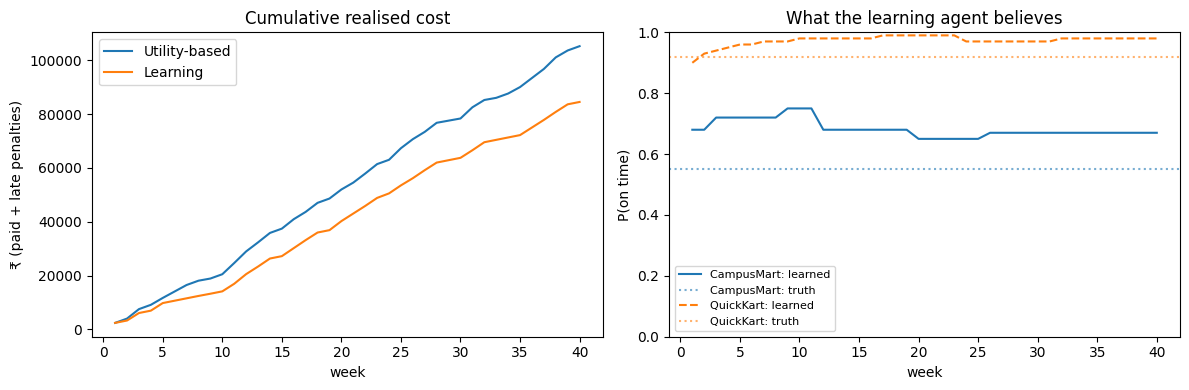

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
weeks = [r["week"] for r in learning_term]
cum = lambda log: pd.Series([r["realised_cost"] for r in log]).cumsum()
ax1.plot(weeks, cum(utility_term), label="Utility-based")
ax1.plot(weeks, cum(learning_term), label="Learning")
ax1.set(title="Cumulative realised cost", xlabel="week", ylabel="₹ (paid + late penalties)")
ax1.legend()

for s, style, colour in (("CampusMart", "-", "tab:blue"), ("QuickKart", "--", "tab:orange")):
    ax2.plot(weeks, [r[f"belief_{s}"] for r in learning_term], style, color=colour, label=f"{s}: learned")
    ax2.axhline(TRUE_ON_TIME[s], linestyle=":", color=colour, alpha=0.6, label=f"{s}: truth")
ax2.set(title="What the learning agent believes", xlabel="week", ylabel="P(on time)", ylim=(0, 1))
ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Was that luck? Run the same term with 10 different delivery seeds.
rows = []
for seed in range(10):
    u = sum(r["realised_cost"] for r in run_term(UtilityBasedAgent(), seed=seed))
    l = run_term(LearningAgent(), seed=seed)
    rows.append({"seed": seed, "utility agent (₹)": round(u),
                 "learning agent (₹)": round(sum(r["realised_cost"] for r in l)),
                 "learning saves (₹)": round(u - sum(r["realised_cost"] for r in l)),
                 "final belief: CampusMart": l[-1]["belief_CampusMart"]})
pd.DataFrame(rows).set_index("seed")

,utility agent (₹),learning agent (₹),learning saves (₹),final belief: CampusMart
seed,,,,
0,105276,84538,20737,0.67
1,110810,98822,11988,0.64
2,110513,101138,9375,0.59
3,114194,106109,8086,0.51
4,103940,94917,9024,0.61
5,121189,105034,16155,0.52
6,111997,93468,18529,0.62
7,110298,103231,7067,0.76
8,107928,90846,17082,0.65


**Read the result:**
- **The utility agent** makes the same choice every week (CampusMart, the cheapest), because the advertised 95% says the risk is low. It pays the late penalty again and again, and never finds out why.
- **The learning agent** starts the same way. Its critic counts the late deliveries and its belief about CampusMart falls. Once the expected late penalty outweighs QuickKart's 10% markup, it **switches suppliers on its own**: it pays a little more and gets far fewer late lines.
- **Its belief stops falling before it reaches the true 55%.** Once it prefers QuickKart, it rarely buys from CampusMart, so it rarely sees new CampusMart deliveries. It has learned *enough to decide*, not the exact number. Only the problem generator's occasional exploration keeps some evidence coming in (Exercise 5).
- **The two utility functions are identical.** The only difference is that one agent's numbers come from experience.

---
## Side by side:  (T1 to T5)

In [ ]:
agents = {"1 Simple reflex": SimpleReflexAgent(), "2 Model-based reflex": ModelBasedReflexAgent(),
          "3 Goal-based": GoalBasedAgent(), "4 Utility-based": UtilityBasedAgent(),
          "5 Learning (new)": LearningAgent()}
table = {name: {r["order"]: r["verdict"] + ("" if r["verdict"] == "escalated" else f"  ₹{r['spent']:,.0f}")
                for r in run_week(agent, verbose=False)}
         for name, agent in agents.items()}
pd.DataFrame(table).T

,T1,T2,T3,T4,T5
1 Simple reflex,"goal met ₹5,978",BROKE BUDGET ₹885,"BROKE BUDGET ₹3,003","SHORT ₹2,119","SHORT ₹1,709"
2 Model-based reflex,"goal met ₹5,978",BROKE BUDGET ₹885,"BROKE BUDGET ₹3,003","goal met ₹5,828","goal met ₹2,912"
3 Goal-based,"goal met ₹5,978",escalated,escalated,"goal met ₹5,828","goal met ₹2,983"
4 Utility-based,"goal met ₹5,978",escalated,escalated,"goal met ₹5,828","goal met ₹2,912"
5 Learning (new),"goal met ₹5,978",escalated,escalated,"goal met ₹5,828","goal met ₹2,983"


| Agent | **It becomes this type when…** | Fixes | Still fails at |
|---|---|---|---|
| **Simple reflex** | it maps the current percept to an action with fixed rules | nothing; it's the baseline | stock it can't see, budget, deadline |
| **Model-based reflex** | it keeps **internal state** (stock after its own orders) and a model of how its actions change the world | short shipments (T4, T5) | budget (T2, T3); meets the deadline only by accident |
| **Goal-based** | it holds an **explicit goal** and uses its model to **look ahead** at whole plans before acting | budget and deadline; escalates the impossible T2, T3 | can't prefer one passing plan over another (T5) |
| **Utility-based** | it scores outcomes with a **utility** and picks the plan with the highest **expected** value | picks the cheaper passing plan on T5 | trusts wrong numbers (advertised on-time rates) forever |
| **Learning** | a **critic** judges outcomes and a **learning element** changes the numbers the agent decides with; a **problem generator** explores | learns the true on-time rates and switches supplier | needs experience: on day one it's just the utility agent |

In the table above, the learning agent's T5 differs from the utility agent's because of the late T1 deliveries it had just seen. Same utility function, different experience.

**Each type includes everything below it.** The learning agent is still model-based (it tracks stock), still goal-based (the goal test is a hard constraint) and still utility-based (it maximises expected utility).

## Where do our LLM agents sit?

The same ladder applies to the ReAct agent from the lab:

| LLM setup | Type | Why |
|---|---|---|
| Bare LLM: prompt in, answer out | **Simple reflex** | maps the input straight to an output; no tools, no state |
| ReAct agent: Thought → Action → Observation | **Model-based** | the scratchpad is its internal state, built from observations it couldn't see at the start |
| ReAct + `goal_test` + `run_goal_driven` (the lab) | **Goal-based** | an explicit goal test; it only stops when the goal passes, otherwise it escalates |
| Generate several candidate answers, score them, keep the best | **Utility-based** | a score instead of pass/fail |
| Reflexion: write a lesson after a failure and keep it for next time | **Learning** | its experience changes how it acts next time |

## LLM-Powered Procurement Agents

Below, we implement a lightweight LLM-powered agent framework using the **Gemini API**. We will show how an LLM agent can act as a **Model-based ReAct agent** that uses a scratchpad (internal state) to read the catalog, decide on purchases, and learn or adapt its decisions over time based on feedback.

In [ ]:
from google import genai
from google.colab import userdata
import json

# Securely load the API key from secrets manager
GOOGLE_API_KEY = userdata.get('GEMINI_KEY')
client = genai.Client(api_key=GOOGLE_API_KEY)

class LLMProcurementAgent:
    def __init__(self):
        self.history = []
        self.believed_stock = {}
        self.week_seen = None

    def update_state(self, catalog):
        if catalog["week"] != self.week_seen:
            self.believed_stock = {(o["supplier"], o["sku"]): o["stock"] for o in catalog["offers"]}
            self.week_seen = catalog["week"]

    def decide(self, order, catalog):
        self.update_state(catalog)

        # Prepare the system prompt describing the world constraints and the current inventory belief
        prompt = f"""
        You are a procurement agent. Your goal is to choose supplier and SKU combinations to fulfill an order.

        Constraints:
        1. Stay under the budget.
        2. Meet the deadline.
        3. Do not order more than the available believed stock.

        Believed Stock:
        {json.dumps({f'{k[0]}:{k[1]}': v for k, v in self.believed_stock.items()}, indent=2)}

        Order Details:
        {json.dumps(order, indent=2)}

        Formulate a valid plan. Respond ONLY in valid JSON format with the key "lines" containing a list of [supplier, sku, qty] tuples, and a "note" explaining your reasoning.
        """

        response = client.models.generate_content(
            model='gemini-3.5-flash',
            contents=prompt,
            config={'response_mime_type': 'application/json'}
        )

        try:
            decision = json.loads(response.text)
        except Exception:
            # Fallback to empty lines if LLM output fails validation
            decision = {"lines": [], "note": "LLM failed to generate valid JSON plan"}

        return decision

    def observe(self, confirmations):
        for c in confirmations:
            self.believed_stock[(c["supplier"], c["sku"])] -= c["shipped"]

# Instantiate and dry-run with T1
llm_agent = LLMProcurementAgent()
world = ProcurementWorld(seed=0)
catalog = world.read_catalog()
decision = llm_agent.decide(ORDERS["T2"], catalog)
print("LLM Agent decision for T2:", json.dumps(decision, indent=2))

LLM Agent decision for T2: {
  "lines": [
    [
      "QuickKart",
      "WB-MRK",
      10
    ],
    [
      "QuickKart",
      "STK-PAD",
      5
    ]
  ],
  "note": "Ordered 10 units of WB-MRK for markers and 5 units of STK-PAD for sticky pads from QuickKart, which has sufficient stock to fulfill the request within the deadline and budget constraints."
}
